# 05 Train the risk model

**Purpose.** Score each transformer at 00:00 for the next 24 h: will it trip? Compare a trained classifier with the `rules` baseline (Critical when the forecast stays above 100% for 2 h).

**Data.** `data/sim/` (dev scale, seed 7), training days only. Labels come from the trip rule (load above 110% for 3 h, silip-domain) on the true load.

**Outcome.** Model settings and tier thresholds in `notebooks/results/05_risk.json`, chosen for recall at an agreed false-alarm budget.

In [1]:
import lightgbm as lgb
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from _data import HOLIDAYS, holdout_start, load_tables
from _features import RISK_FEATURES, trip_labels
from _models import SEED, load_table, read_result, recall_and_false_alarms, risk_examples, rolling_day_ahead, save_result
from _style import COLORS, label
from sklearn.metrics import average_precision_score, brier_score_loss

tables = load_tables()
load, transformers = tables["load"], tables["transformers"]
cutoff = holdout_start(load)
load = load[load["ts"] < cutoff]
load_params = read_result("04_load_forecast")["params"]
table = load_table(load, HOLIDAYS)
table = table[table["ts"] >= table["ts"].min() + pd.Timedelta(days=7)]
FIRST_DAY = table["ts"].min().normalize() + pd.Timedelta(days=7)  # each forecaster gets at least a week
VALID_START = cutoff - pd.Timedelta(days=7)

## Train on what scoring will see
The scorer reads a *forecast*, not the actual load. Training on actual load would teach it sharper peaks than forecasts ever show. So each training day gets a day-ahead forecast from a load model refit weekly on the days before it, the same way the scoring job works.

In [2]:
forecasts = rolling_day_ahead(table, load_params, FIRST_DAY, cutoff)
labels = trip_labels(load, transformers)
examples = risk_examples(forecasts, transformers, labels)
train = examples[examples["day"] < VALID_START]
valid = examples[examples["day"] >= VALID_START]
print(f"{len(examples):,} transformer-days from {FIRST_DAY:%Y-%m-%d}; train {len(train):,}, validate {len(valid):,}")
examples[RISK_FEATURES + ["tripped"]].describe().T.round(2)

1,750 transformer-days from 2026-04-15; train 1,400, validate 350


,count,mean,std,min,25%,50%,75%,max
peak_load_pct,1750.0,0.94,0.30,0.26,0.73,0.89,1.11,2.53
mean_load_pct,1750.0,0.42,0.15,0.12,0.31,0.40,0.51,0.97
hours_over_100,1750.0,0.96,1.58,0.00,0.00,0.00,1.75,6.75
hours_over_110,1750.0,0.58,1.23,0.00,0.00,0.00,0.25,6.00
hours_over_90,1750.0,1.81,2.59,0.00,0.00,0.00,3.25,15.50
coverage_pct,1750.0,0.60,0.21,0.09,0.43,0.61,0.79,0.97
rated_kva,1750.0,74.00,23.57,25.00,50.00,75.00,100.00,100.00


## How rare are trips?

In [3]:
balance = examples.groupby(examples["day"] >= VALID_START)["tripped"].agg(["sum", "count", "mean"])
balance.index = ["train", "validate"]
balance.columns = ["trips", "transformer-days", "trip share"]
balance.round(3)

,trips,transformer-days,trip share
train,116,1400,0.083
validate,91,350,0.260


Takeaway: under one in ten transformer-days trips, so accuracy is meaningless. We judge recall of trips against false alarms per transformer-month.

## The rules baseline on the same forecasts

In [4]:
rules_flag = examples["hours_over_100"] * 4 >= 8  # forecast above 100% for 2 h
rules_valid = recall_and_false_alarms(rules_flag[valid.index], valid["tripped"])
rules_train = recall_and_false_alarms(rules_flag[train.index], train["tripped"])
pd.DataFrame({"train days": rules_train, "validation days": rules_valid}).round(3)

,train days,validation days
recall,0.655,0.912
false_alarms_per_tx_month,4.157,5.914
trips,116.000,91.000
windows,1400.000,350.000


Takeaway: the rules catch most trips, but they also flag many transformer-days that never trip: a forecast just above 100% for 2 h often does not reach 110% for 3 h. The question for a model is whether it can catch as many trips with fewer false alarms.

## Class imbalance: weight the rare class or not?
LightGBM classifiers, same settings, with and without `is_unbalance`. Compared by average precision (area under the precision-recall curve) on the validation days.

In [5]:
BASE = {"n_estimators": 200, "learning_rate": 0.05, "num_leaves": 15, "min_child_samples": 20}


def fit_risk(frame: pd.DataFrame, params: dict) -> lgb.LGBMClassifier:
    model = lgb.LGBMClassifier(**params, random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1)
    return model.fit(frame[RISK_FEATURES].to_numpy(dtype=np.float64), frame["tripped"].astype(int))


candidates = {
    "unweighted": BASE,
    "is_unbalance": {**BASE, "is_unbalance": True},
    "unweighted, smaller trees": {**BASE, "num_leaves": 7, "min_child_samples": 40},
}
comparison, probabilities = [], {}
for name, params in candidates.items():
    p = fit_risk(train, params).predict_proba(valid[RISK_FEATURES].to_numpy(dtype=np.float64))[:, 1]
    probabilities[name] = p
    comparison.append({"model": name, "average precision": average_precision_score(valid["tripped"], p), "Brier score": brier_score_loss(valid["tripped"], p)})
comparison = pd.DataFrame(comparison).set_index("model")
comparison.round(3)

,average precision,Brier score
model,,
unweighted,0.799,0.118
is_unbalance,0.797,0.110
"unweighted, smaller trees",0.840,0.107


In [6]:
chosen_name = comparison["average precision"].idxmax()
risk_params = candidates[chosen_name]
p_valid = probabilities[chosen_name]
print(f"chosen: {chosen_name}")

chosen: unweighted, smaller trees


## Calibration: does a 30% score mean 30% of those trip?

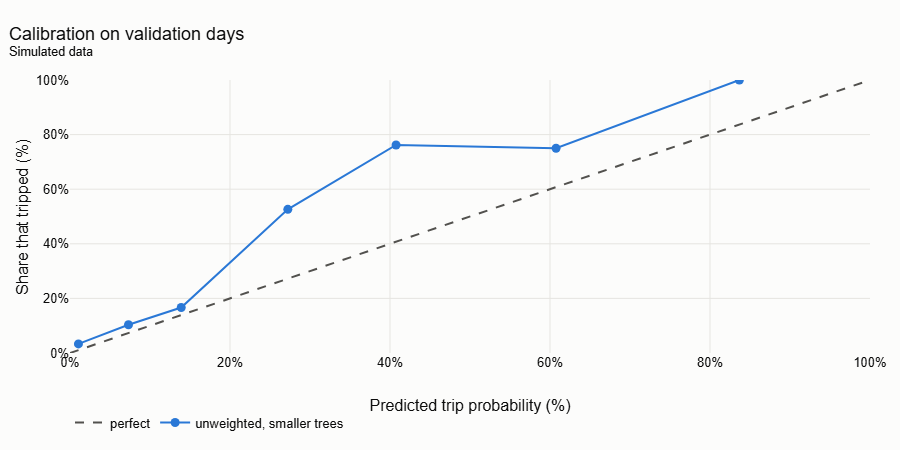

,predicted,observed,n
0,0.011,0.033,180
1,0.073,0.103,29
2,0.139,0.167,36
3,0.272,0.526,38
4,0.408,0.762,21
5,0.608,0.750,24
6,0.837,1.000,22


In [7]:
bins = pd.cut(p_valid, [0, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0], include_lowest=True)
reliability = pd.DataFrame({"p": p_valid, "tripped": valid["tripped"].to_numpy()}).groupby(bins, observed=True).agg(predicted=("p", "mean"), observed=("tripped", "mean"), n=("p", "size")).reset_index(drop=True)
fig = go.Figure()
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line={"dash": "dash", "color": "#52514e"}, name="perfect"))
fig.add_trace(go.Scatter(x=reliability["predicted"], y=reliability["observed"], mode="lines+markers", marker={"size": 9, "color": COLORS[0]}, line={"color": COLORS[0]}, name=chosen_name, text=reliability["n"], hovertemplate="n=%{text}"))
fig.update_xaxes(tickformat=".0%", range=[0, 1])
fig.update_yaxes(tickformat=".0%", range=[0, 1])
label(fig, "Calibration on validation days", "Predicted trip probability (%)", "Share that tripped (%)").show()
reliability.round(3)

Takeaway: the model under-predicts in the middle range (the validation week was hotter than the training weeks, so trips were more common). Tiers use thresholds chosen for recall and false alarms below, so they do not need exact probabilities; the number is treated as a score, not a probability.

## Choose the Critical threshold
The project rule: a model ships only if it does not lower recall, and it should not raise false alarms. So the budget is the rules baseline's own false-alarm rate on the validation days, and we pick the threshold with the most recall inside it. Engineers may want a tighter budget later `[VERIFY]`; the curve shows what each choice costs.

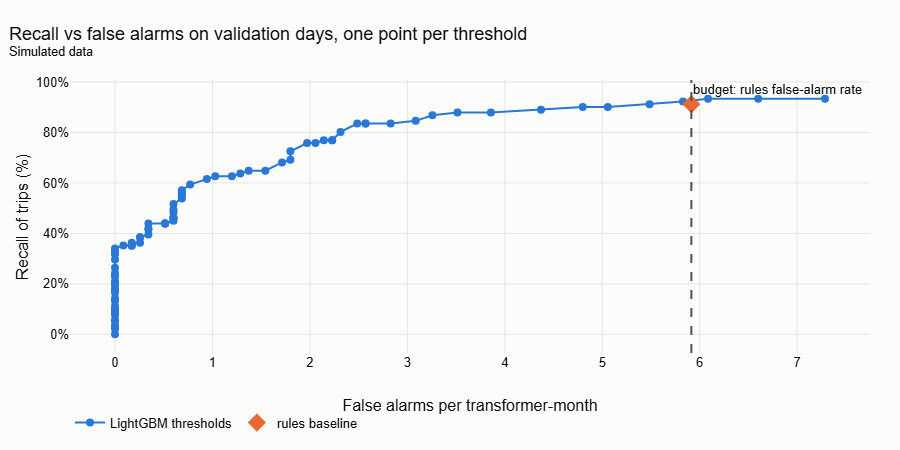

Critical at score >= 0.08, Watch at >= 0.04


In [8]:
FALSE_ALARM_BUDGET = rules_valid["false_alarms_per_tx_month"]  # no more false alarms than the baseline
curve = pd.DataFrame([{"threshold": t, **recall_and_false_alarms(pd.Series(p_valid >= t), valid["tripped"].reset_index(drop=True))} for t in np.round(np.arange(0.05, 0.96, 0.01), 2)])
within = curve[curve["false_alarms_per_tx_month"] <= FALSE_ALARM_BUDGET]
critical = float(within.sort_values(["recall", "threshold"], ascending=[False, True])["threshold"].iloc[0])
watch = round(critical / 2, 2)  # Watch tier: half the Critical score [VERIFY] with engineers
fig = go.Figure()
fig.add_trace(go.Scatter(x=curve["false_alarms_per_tx_month"], y=curve["recall"], mode="lines+markers", marker={"size": 8, "color": COLORS[0]}, line={"color": COLORS[0]}, name="LightGBM thresholds"))
fig.add_trace(go.Scatter(x=[rules_valid["false_alarms_per_tx_month"]], y=[rules_valid["recall"]], mode="markers", marker={"size": 14, "color": COLORS[1], "symbol": "diamond"}, name="rules baseline"))
fig.add_vline(x=FALSE_ALARM_BUDGET, line_dash="dash", line_color="#52514e", annotation_text="budget: rules false-alarm rate")
fig.update_yaxes(tickformat=".0%")
label(fig, "Recall vs false alarms on validation days, one point per threshold", "False alarms per transformer-month", "Recall of trips (%)").show()
print(f"Critical at score >= {critical}, Watch at >= {watch}")

## Recall at 12 hours or more of warning
Scored at 00:00, a trip that completes at 12:00 or later was flagged at least 12 h ahead (the SPEC target).

In [9]:
flag_model = pd.Series(p_valid >= critical, index=valid.index)
lead_h = (valid["trip_ts"] - valid["day"]).dt.total_seconds() / 3600
early = valid["tripped"] & (lead_h >= 12)
summary = pd.DataFrame({
    "rules": {**rules_valid, "recall at >= 12 h lead": (rules_flag[valid.index] & early).sum() / early.sum()},
    "lightgbm": {**recall_and_false_alarms(flag_model, valid["tripped"]), "recall at >= 12 h lead": (flag_model & early).sum() / early.sum()},
}).T
summary.round(3)

,recall,false_alarms_per_tx_month,trips,windows,recall at >= 12 h lead
rules,0.912,5.914,91.0,350.0,0.912
lightgbm,0.923,5.829,91.0,350.0,0.923


Takeaway: inside the same false-alarm budget the model catches at least as many trips as the rules, and the curve shows how many false alarms each lower threshold saves. Trips come in the evening, so every catch at 00:00 gives 12 h or more of warning.

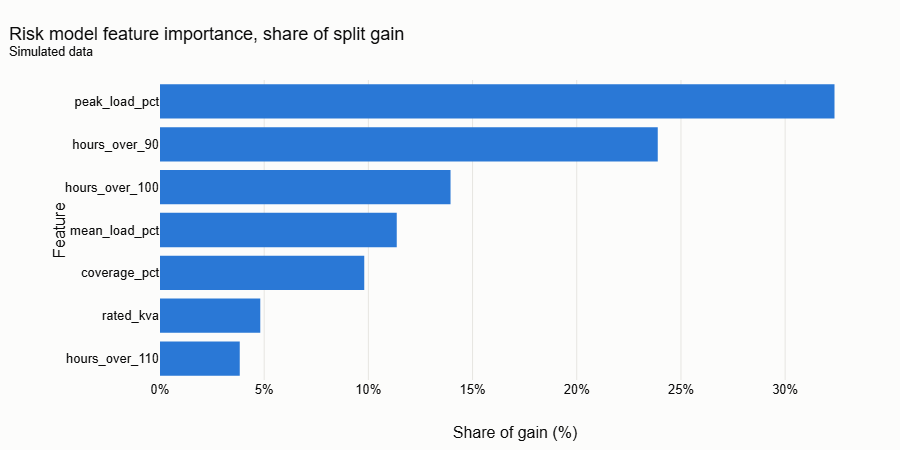

In [10]:
importance = pd.DataFrame({"feature": RISK_FEATURES, "gain": fit_risk(train, risk_params).booster_.feature_importance("gain")})
importance["share"] = importance["gain"] / importance["gain"].sum()
fig = px.bar(importance.sort_values("share"), x="share", y="feature", orientation="h", color_discrete_sequence=COLORS[:1])
fig.update_xaxes(tickformat=".0%")
fig.update_layout(margin={"l": 160})
label(fig, "Risk model feature importance, share of split gain", "Share of gain (%)", "Feature").show()

In [11]:
save_result("05_risk", {
    "chosen": "lightgbm",
    "variant": chosen_name,
    "params": risk_params,
    "features": RISK_FEATURES,
    "thresholds": {"critical": critical, "watch": watch},
    "false_alarm_budget_per_tx_month": FALSE_ALARM_BUDGET,
    "first_training_day": str(FIRST_DAY),
    "validation": summary.round(4).to_dict("index"),
})

**Outcome.** A LightGBM classifier on forecast-window features, with a Critical threshold set for the false-alarm budget. `06` retrains it on every training day and checks it once on the held-out week.